In [1]:
import numpy as np
import matplotlib.pyplot as plt
from bat_hd.random_walk import generate_bat_flight, split_flight_data
from bat_hd.bat_hd_system import (
    BatHeadDirectionSystem,
    sphere_to_toroid,
    BatHDSystemConfig,
)
from bat_hd.plot_tools import smooth_ts
import os
from concurrent.futures import ThreadPoolExecutor
from typing import Dict, Any, List, Tuple, Iterable, Union
from tqdm import tqdm
plt.rcParams.update(
    {
        "font.family": "Helvetica",
        "font.size": 12,
    }
)

DATA_DIR = "../simulation_data/darkness"
PLOTS_DIR = "../plots/darkness"
os.makedirs(PLOTS_DIR, exist_ok=True)
os.makedirs(DATA_DIR, exist_ok=True)

In [2]:
dt = 0.5e-3
n = (256, 128)
intrinsic_noise = 0.01
input_noise = 0.1
n_conj = (20, 10)
n_landmarks = 40
interval = 10
rng = np.random.default_rng(seed=0)

conj_grid_config = BatHDSystemConfig(
    dt=dt,
    n_ring=n,
    input_noise=input_noise,
    intrinsic_noise=intrinsic_noise,
    n_conjunctive=n_conj,
    n_landmark=n_landmarks,
    conj_feedback_strength=4,
    ring_conj_projection_strength=1,
    conj_gain=3,
    ring_input_strength=(0.5, 0.2),
    vision_gated=True,
    feedback_mode="conjunctive_grid",
)


direct_feedback_config = BatHDSystemConfig(
    dt=dt,
    n_ring=n,
    input_noise=input_noise,
    intrinsic_noise=intrinsic_noise,
    n_conjunctive=n_conj,
    n_landmark=n_landmarks,
    ring_input_strength=(0.5, 0.5),
    vision_gated=True,
    feedback_mode="direct",
)

conj_grid_system = BatHeadDirectionSystem(conj_grid_config)
direct_feedback_system = BatHeadDirectionSystem(direct_feedback_config)




In [3]:
T_total = 400
T_dark = 200

bat_flight = generate_bat_flight(
    T=T_total,
    dt=dt)

light_flight_data, dark_flight_data = split_flight_data(bat_flight, split_time=T_dark)


Generating bat flight: 100%|██████████| 799999/799999 [00:56<00:00, 14069.75it/s]


In [4]:
conj_grid_system.warm_up(initial_dir = light_flight_data["dir_sphere"][0])
direct_feedback_system.warm_up(initial_dir = light_flight_data["dir_sphere"][0])

In [5]:
light_records_conj = conj_grid_system.run_simulation(light_flight_data,interval=interval)
light_records_direct = direct_feedback_system.run_simulation(light_flight_data,interval=interval)

dark_records_conj = conj_grid_system.run_simulation(dark_flight_data,interval=interval, use_anchor=False)
dark_records_direct = direct_feedback_system.run_simulation(dark_flight_data,interval=interval, use_anchor=False)

Running Simulation Steps: 100%|██████████| 400000/400000 [01:25<00:00, 4694.21it/s]


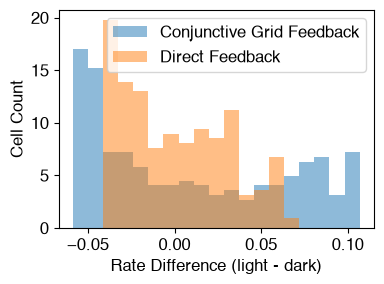

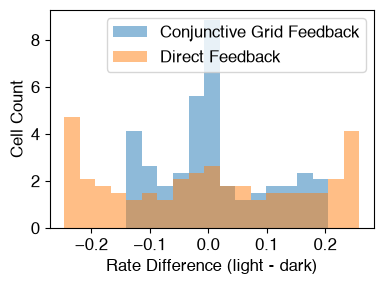

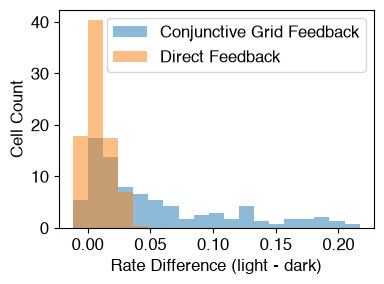

In [14]:
nbins = 20
for cell_type in ["yaw_cells", "pitch_cells", "conj_cells"]:
    conj_grid_mean_rate_light = np.mean(light_records_conj[cell_type], axis=0)
    direct_feedback_mean_rate_light = np.mean(light_records_direct[cell_type], axis=0)

    conj_grid_mean_rate_dark = np.mean(dark_records_conj[cell_type], axis=0)
    direct_feedback_mean_rate_dark = np.mean(dark_records_direct[cell_type], axis=0)
    rate_diff_conj = conj_grid_mean_rate_light - conj_grid_mean_rate_dark
    rate_diff_direct = direct_feedback_mean_rate_light - direct_feedback_mean_rate_dark
    xmin = min(rate_diff_conj.min(), rate_diff_direct.min())
    xmax = max(rate_diff_conj.max(), rate_diff_direct.max())
    bins = np.linspace(xmin, xmax, nbins)


    fig, ax = plt.subplots(1, figsize=(4,3))
    ax.hist(rate_diff_conj.flatten(), bins=bins, alpha=0.5, label="Conjunctive Grid Feedback",density=True)
    ax.hist(rate_diff_direct.flatten(), bins=bins, alpha=0.5, label="Direct Feedback",density=True)
    ax.set_xlabel("Rate Difference (light - dark)")
    ax.set_ylabel("Cell Count")
    ax.legend()
    fig.tight_layout()
    fig.savefig(os.path.join(PLOTS_DIR, f"{cell_type}_rate_difference_histogram.svg"))